# Task 3

Adam Oakes

# Library Imports

In [ ]:
import keras, pathlib, os
from keras import layers
from keras.utils import image_dataset_from_directory
from pathlib import Path
import matplotlib.pyplot as plt
import tensorflow as tf

# Load the Data

In [ ]:
image_size = (180, 180)
batch_size = 64
data_dir = pathlib.Path("../data")

train_dataset = image_dataset_from_directory(
    data_dir / "train", image_size=image_size, batch_size=batch_size
)
validation_dataset = image_dataset_from_directory(
    data_dir / "validation", image_size=image_size, batch_size=batch_size
)
test_dataset = image_dataset_from_directory(
    data_dir / "test", image_size=image_size, batch_size=batch_size
)

# Building the model

In [ ]:
nb_path = os.environ.get("JPY_SESSION_NAME")   # full path to the .ipynb
nb_name = os.path.basename(nb_path) if nb_path else None
task = Path(nb_name).stem

checkpoints = Path("../checkpoints/" + task)
checkpoints.mkdir(parents=True, exist_ok=True)

plots = Path("..plots/" + task)
plots.mkdir(parents=True, exist_ok=True)

In [ ]:
inputs = keras.Input(shape=(180, 180, 3))
x = layers.Rescaling(1.0 / 255)(inputs)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=512, kernel_size=3, activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model_1 = keras.Model(inputs=inputs, outputs=outputs, name="Model-1")

model_1.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=(checkpoints / (model.name + ".keras")),
        save_best_only=True,
        monitor="val_loss",
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=3,
        mode='max',
        restore_best_weights=True
    )
]

In [42]:
model_1.summary()

Model: "model_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_6 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_26 (MaxPooling2D) │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_27 (MaxPooling2D) │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 7, 7, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,707,269 (17.96 MB)

 Trainable params: 1,569,089 (5.99 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,138,180 (11.97 MB)

In [43]:
inputs = keras.Input(shape=(180, 180, 3))
x = layers.Rescaling(1.0 / 255)(inputs)
x = layers.Conv2D(filters=8, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=16, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model_2 = keras.Model(inputs=inputs, outputs=outputs, name="Model-2")

model_2.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=(checkpoints / (model_2.name + ".keras")),
        save_best_only=True,
        monitor="val_loss",
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=3,
        mode='max',
        restore_best_weights=True
    )
]

In [44]:
model_2.summary()

Model: "Model-2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_9 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_43 (Conv2D)              │ (None, 178, 178, 8)    │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 89, 89, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_44 (Conv2D)              │ (None, 87, 87, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 43, 43, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_45 (Conv2D)              │ (None, 41, 41, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_9      │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,065 (23.69 KB)

 Trainable params: 6,065 (23.69 KB)

 Non-trainable params: 0 (0.00 B)

# Training the model on the original dataset

In [ ]:
history_1 = model_1.fit(
    train_dataset,
    epochs=4,
    validation_data=validation_dataset,
    callbacks=callbacks,
)

In [47]:
history_2 = model_2.fit(
    train_dataset,
    epochs=20,
    validation_data=validation_dataset,
    callbacks=callbacks,
)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 215s 172ms/step - accuracy: 0.8136 - loss: 0.4198 - val_accuracy: 0.8167 - val_loss: 0.4040
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 237s 190ms/step - accuracy: 0.8289 - loss: 0.3926 - val_accuracy: 0.8437 - val_loss: 0.3742
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 261s 208ms/step - accuracy: 0.8386 - loss: 0.3759 - val_accuracy: 0.8472 - val_loss: 0.3674
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 252s 201ms/step - accuracy: 0.8458 - loss: 0.3605 - val_accuracy: 0.8577 - val_loss: 0.3400
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 255s 204ms/step - accuracy: 0.8549 - loss: 0.3460 - val_accuracy: 0.8587 - val_loss: 0.3313
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 259s 207ms/step - accuracy: 0.8588 - loss: 0.3367 - val_accuracy: 0.8586 - val_loss: 0.3454
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 257s 205ms/step - accuracy: 0.8613 - loss: 0.3298 - val_accuracy: 0.8641 - val_loss: 0.3295
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 258s 206ms/step - ac

In [ ]:
print(history_1.history["val_accuracy"][-1])

# Learning curves

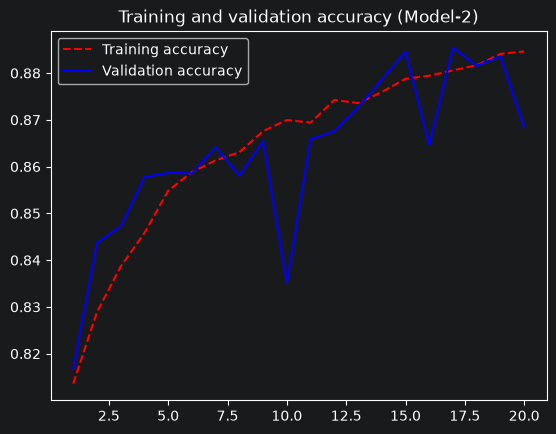

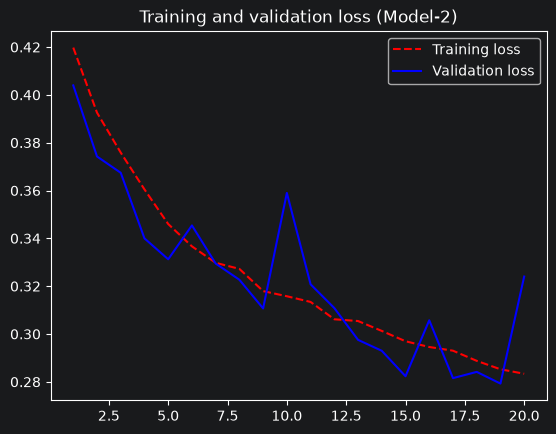

In [48]:
history = history_2
model = model_2

accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(accuracy) + 1)
plt.plot(epochs, accuracy, "r--", label="Training accuracy")
plt.plot(epochs, val_accuracy, "b", label="Validation accuracy")
plt.title("Training and validation accuracy (" + model.name + ")")
plt.legend()
plt.figure()
plt.plot(epochs, loss, "r--", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Training and validation loss (" + model.name + ")")
plt.legend()
plt.show()


fig.savefig(plots / (model.name + ".png"))

# Data Augmentation

## Defining a data augmentation stage

In [ ]:
data_augmentation_layers = [
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2),
]

def data_augmentation(images, targets):
    for layer in data_augmentation_layers:
        images = layer(images)
    return images, targets

augmented_train_dataset = train_dataset.map(
    data_augmentation, num_parallel_calls=8
)
augmented_train_dataset = augmented_train_dataset.prefetch(tf.data.AUTOTUNE)

## Displaying some randomly augmented training images

In [ ]:
plt.figure(figsize=(10, 10))
for image_batch, _ in train_dataset.take(1):
    image = image_batch[0]
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        augmented_image, _ = data_augmentation(image, None)
        augmented_image = keras.ops.convert_to_numpy(augmented_image)
        plt.imshow(augmented_image.astype("uint8"))
        plt.axis("off")

## Note

If you train a new model using this data augmentation con.guration, the model will
never see the same input twice. But the inputs it sees are still heavily intercorrelated,
because they come from a small number of original images—you can’t produce new
information; you can only remix existing information.

# Training the model on the augmented dataset

In [ ]:
history_1 = model_1.fit(
    augmented_train_dataset,
    epochs=4,
    validation_data=validation_dataset,
    callbacks=callbacks,
)